# Logistics Data Analysis Assessment 
#### Isha Chaudhary

### Importing Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as plty
# %pip install seaborn
# %pip install plotly
import seaborn as sns
import math

In [ ]:
orders = pd.read_csv('Logistics data/Data-Table 1.csv')
refs = pd.read_csv('Logistics data/References-Table.csv')

### Renaming columns

In [ ]:
orders = orders.rename(columns={
    "Order #": "order_no",
    "Product Type": "product_type",
    "Month to Sell": "month_to_sell",
    "Units": "units",
    "Cubic Meters": "order_size",
    "Country of Origin": "country",
    "Earliest Collection Date": "collection_date"
})

orders.columns

Index(['order_no', 'product_type', 'month_to_sell', 'units', 'order_size',
       'country', 'collection_date', 'SellingDate', 'ColDate'],
      dtype='object')

In [ ]:
refs = refs.rename(columns={
    "Country of Origin": "country",
    "Lead Time (Days) to Store": "lead_time_days",
    "Lane Rate ($ per container)": "lane_rate"
})

refs.columns

Index(['country', 'lead_time_days', 'lane_rate'], dtype='object')

In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_no         20000 non-null  int64         
 1   product_type     20000 non-null  object        
 2   month_to_sell    20000 non-null  datetime64[ns]
 3   units            20000 non-null  int64         
 4   order_size       20000 non-null  float64       
 5   country          20000 non-null  object        
 6   collection_date  20000 non-null  datetime64[ns]
 7   SellingDate      20000 non-null  period[M]     
 8   ColDate          20000 non-null  period[M]     
dtypes: datetime64[ns](2), float64(1), int64(2), object(2), period[M](2)
memory usage: 1.4+ MB


### Changing datetime format
Assuming the date in the column 'month to sell' is the first day of the month

In [ ]:
orders["collection_date"] = pd.to_datetime(orders["collection_date"])
orders["month_to_sell"] = pd.to_datetime(orders["month_to_sell"])

In [ ]:
orders.head()

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate
0,1,Apparel,2025-11-01,9839,57.6,Malaysia,2025-09-11,2025-11,2025-09
1,2,Apparel,2026-05-01,11200,51.0,Canada,2026-02-01,2026-05,2026-02
2,3,Apparel,2026-03-01,2353,24.0,India,2025-10-27,2026-03,2025-10
3,4,Shoes,2025-07-01,1506,36.0,Indonesia,2025-05-05,2025-07,2025-05
4,5,Shoes,2025-11-01,7697,25.8,Paraguay,2025-07-24,2025-11,2025-07


## Missing Values

In [ ]:
orders.isnull().sum()

order_no           0
product_type       0
month_to_sell      0
units              0
order_size         0
country            0
collection_date    0
SellingDate        0
ColDate            0
dtype: int64

In [ ]:
refs.isnull().sum()

country           0
lead_time_days    0
lane_rate         0
dtype: int64

No missing values in either of the datasets.

## Merging the two tables

#### Checking if the countries occuring in both the sheets match or are unique

In [ ]:
print("Number of unique countries in orders =", len(orders["country"].unique()))
print("Number of unique countries in reference =", len(refs["country"].unique()))

Number of unique countries in orders = 26
Number of unique countries in reference = 26


In [ ]:
set(orders["country"]) - set(refs["country"])

set()

In [ ]:
merged_data = orders.merge(refs, on="country", how="left")
merged_data.head()

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate
0,1,Apparel,2025-11-01,9839,57.6,Malaysia,2025-09-11,2025-11,2025-09,50,"£1,200.00"
1,2,Apparel,2026-05-01,11200,51.0,Canada,2026-02-01,2026-05,2026-02,60,"£1,200.00"
2,3,Apparel,2026-03-01,2353,24.0,India,2025-10-27,2026-03,2025-10,68,"£1,000.00"
3,4,Shoes,2025-07-01,1506,36.0,Indonesia,2025-05-05,2025-07,2025-05,65,"£1,100.00"
4,5,Shoes,2025-11-01,7697,25.8,Paraguay,2025-07-24,2025-11,2025-07,59,"£1,200.00"


# Initial Observations

In [ ]:
print("Number of unique countries =", len(merged_data["country"].unique()))

Number of unique countries = 26


In [ ]:
merged_data["country"].value_counts()

country
China             1915
India             1392
Vietnam           1186
Indonesia          939
Brazil             910
Bangladesh         894
Japan              735
Cambodia           727
Sri Lanka          723
Malaysia           715
Thailand           708
Hong Kong          706
Uruguay            701
United States      693
Paraguay           684
South Korea        624
Columbia           624
Venezuela          619
Singapore          600
Ecuador            589
Bolivia            585
Argentinia         571
Peru               565
Philippines        561
Canada             540
Chile              494
Name: count, dtype: int64

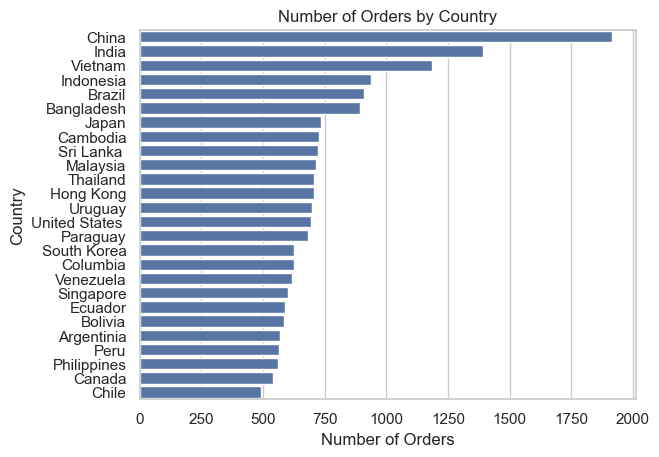

In [ ]:
sns.countplot(
    data=merged_data,
    y="country",
    order=merged_data["country"].value_counts().index
)

plt.title("Number of Orders by Country")
plt.xlabel("Number of Orders")
plt.ylabel("Country")
plt.show()

The company receives the highest number of products from <b>China, India and Vietnam</b>, China being in the lead with a significantly high number. It receives the lowest number of products from <b>Chile</b> out of all 26 countries. In the given duration, rest of the <b>22 countries</b> contributed <b>between 500-1250 orders</b> to the company.

In [ ]:
merged_data["product_type"].value_counts()

product_type
Apparel    5730
Home       4940
Shoes      4823
Gifting    4507
Name: count, dtype: int64

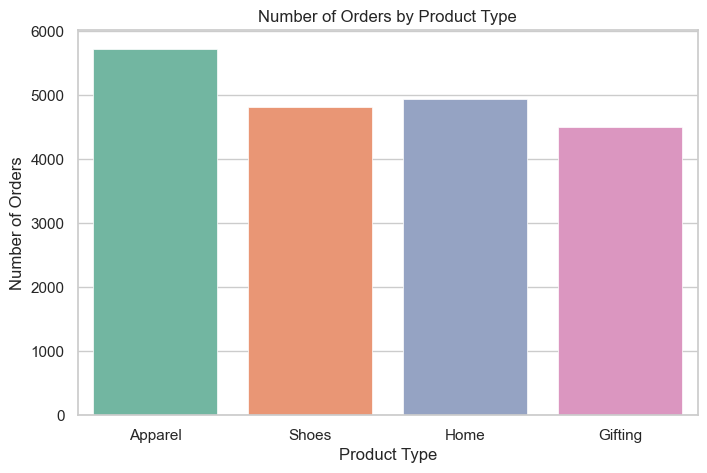

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=merged_data,
    x="product_type",
    hue="product_type",
    palette="Set2",
    legend=False,
    linewidth=0.5
)

plt.title("Number of Orders by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Number of Orders")
plt.show()

Apparel makes up the highest number of orders and shoes, home and gifting follow closely. They have a difference of about a 1000 orders. 

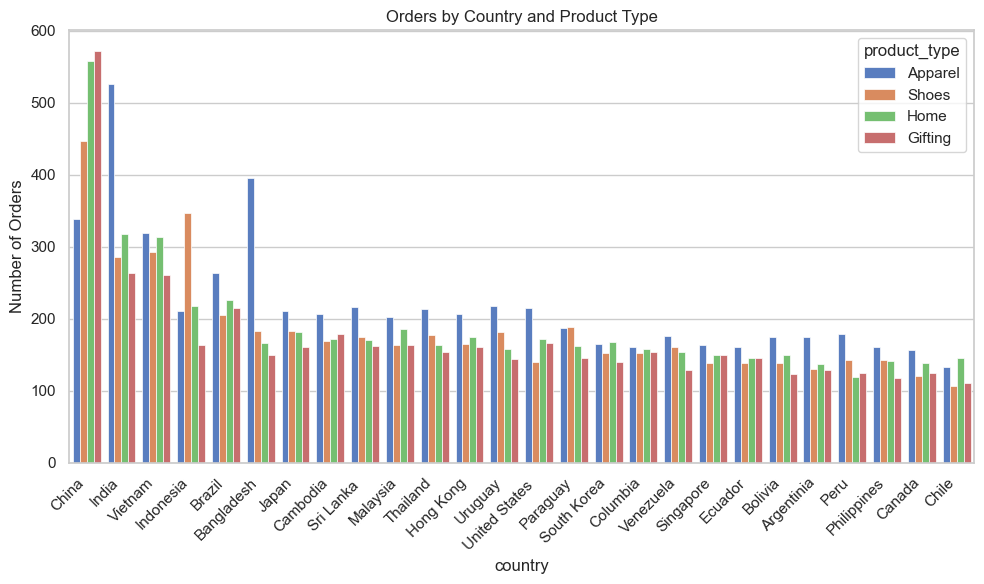

In [ ]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.countplot(
    data=merged_data,
    x="country",
    hue="product_type",
    palette="muted",
    order=merged_data["country"].value_counts().index,
    linewidth=0.5
)

plt.xticks(rotation=45, ha="right")
plt.title("Orders by Country and Product Type")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

We can see <b>apparel has the highest number of order</b> from almost every country. The most significant exclusion is <b>China</b> whose highest number of order is made up of gifting and lowest number of order is made up of apparel. In all cases except <b>Indonesia</b>, the difference in the number of order of product type shoes, home and gifting is low. <b>Indonesia</b> is the second highest exporter of shoes and <b>Bangladesh</b> is the second highest exporter of apparels to the company behind China although both of these countries do not make up the <b>top 3</b> exporters when the <b>product types are combined.</b>

## Observation on Dates

* Earliest month to sell us July 2025 and latest month to sell is June 2026
* Earliest collection date is 11th February, 2025 and latest collection date is 2nd May, 2026.

In [ ]:
earliest_date = orders['month_to_sell'].min()
latest_date = orders['month_to_sell'].max()

print("Earliest date to sell:", earliest_date)
print("Latest date to sell:", latest_date)

Earliest date to sell: 2025-07-01 00:00:00
Latest date to sell: 2026-06-01 00:00:00


In [ ]:
earliest_date = orders['collection_date'].min()
latest_date = orders['collection_date'].max()

print("Earliest date for collection:", earliest_date)
print("Latest date for collection:", latest_date)

Earliest date for collection: 2025-02-11 00:00:00
Latest date for collection: 2026-05-02 00:00:00


In [ ]:
orders['SellingDate'] = orders['month_to_sell'].dt.to_period('M')
monthly_orders = orders.groupby('SellingDate').size().reset_index(name='Number of Orders')
monthly_orders


,SellingDate,Number of Orders
0,2025-07,1617
1,2025-08,1737
2,2025-09,1696
3,2025-10,1665
4,2025-11,3651
5,2025-12,2734
6,2026-01,445
7,2026-02,337
8,2026-03,1239
9,2026-04,1212


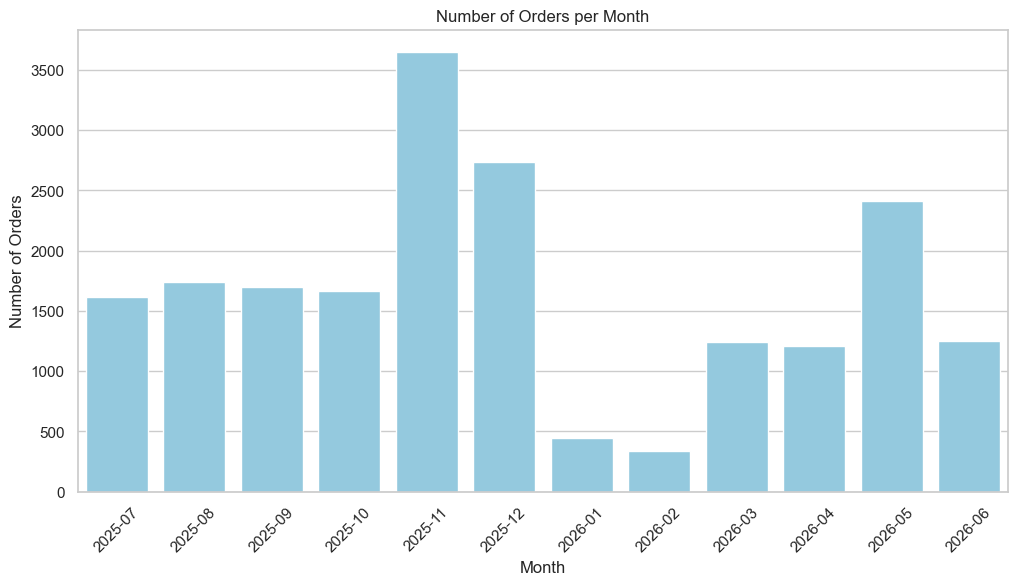

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=monthly_orders['SellingDate'].astype(str), y=monthly_orders['Number of Orders'], color='skyblue')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.title('Number of Orders per Month')
plt.xticks(rotation=45)
plt.show()

* There is a clear <b>spike</b> during the month of <b>November and December</b> which are supposed to sell the highest number of products. There a <b>significant fall during January and February</b>, soon after the festive period where the number of orders fall below 500. The orders are slightly higher during March and April, spike during May and dips back down during June. From July to October, the order numbers are higher and steady.

In [ ]:
orders['ColDate'] = orders['collection_date'].dt.to_period('M')
monthly_collections = orders.groupby('ColDate').size().reset_index(name='Number of Orders')
monthly_collections

,ColDate,Number of Orders
0,2025-02,36
1,2025-03,431
2,2025-04,1074
3,2025-05,1686
4,2025-06,1718
5,2025-07,2161
6,2025-08,2749
7,2025-09,2420
8,2025-10,1227
9,2025-11,609


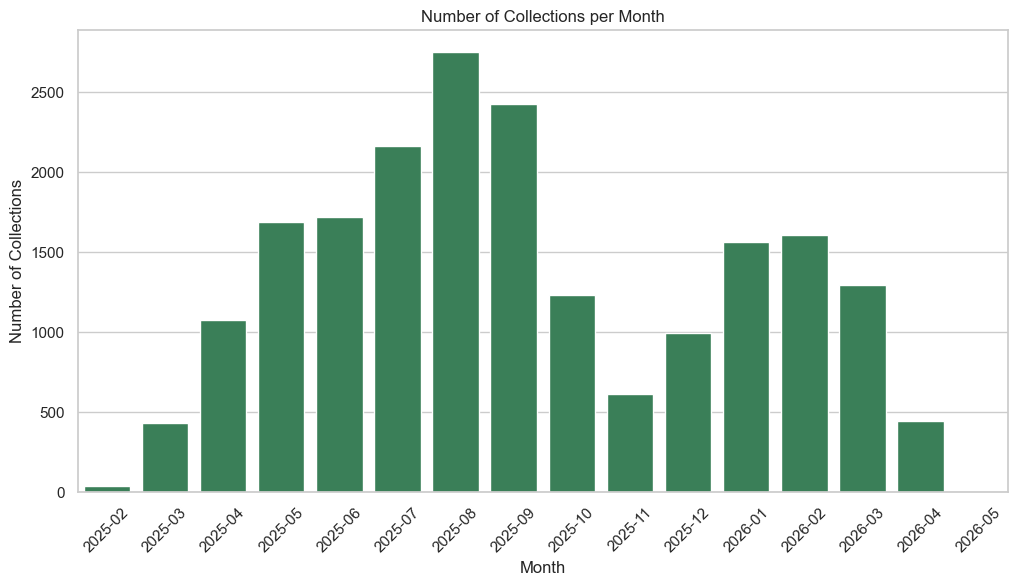

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=monthly_collections['ColDate'].astype(str), y=monthly_collections['Number of Orders'], color='seagreen')
plt.xlabel('Month')
plt.ylabel('Number of Collections')
plt.title('Number of Collections per Month')
plt.xticks(rotation=45)
plt.show()

In [ ]:
len(imputed_data[(merged_data['collection_date'].dt.year == 2025) & (merged_data['collection_date'].dt.month == 2)])

36

The collection date bar plot <b>peaks</b> before the festive months <b>during July, August and September</b> which makes sense because these are the earliest collection dates after which they are shipped to the location of the store which takes them their respective lead time, which we will look into later. It <b>dips</b> during the months <b>October and November</b>. It has a <b>slight increase during January and February of 2026 unlike the February of the previous year</b> where it seems to have the <b>least amount of orders</b> in a month(<b>36 orders</b>).

## Observation on Order Size (Cubic Meters)

In [ ]:
print("Minimum order size = ", merged_data.order_size.min())
print("Maximum order size = ", merged_data.order_size.max())
print("Mean order size = ", merged_data.order_size.mean())
print("Median order size = ", merged_data.order_size.median())

Minimum order size =  0.0
Maximum order size =  60.0
Mean order size =  29.797889
Median order size =  29.4


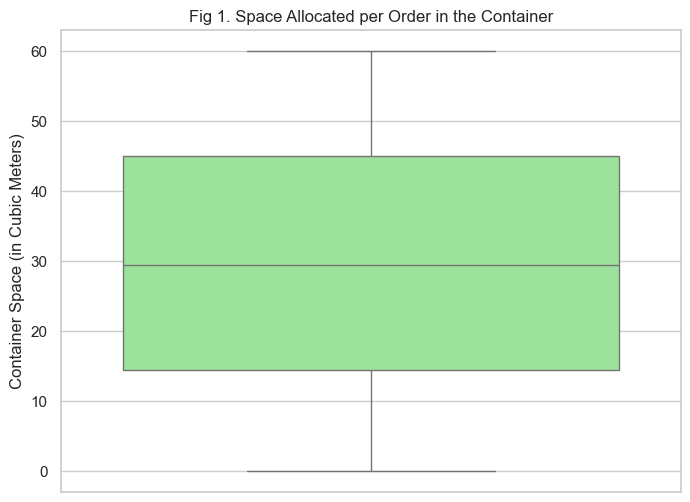

In [ ]:
plt.figure(figsize=(8,6))

sns.boxplot(
    y=orders['order_size'],
    color='lightgreen'
)

plt.ylabel("Container Space (in Cubic Meters)")
plt.title("Fig 1. Space Allocated per Order in the Container")

plt.show()

- The graph shows the <b>lower whisker to be 0 cubic meters</b> and the <b>upper whisker to be 60 cubic meters</b> which represents the smallest and largest typical order sizes in the data. The <b>median</b> of the order sizes is <b>around 29 cubic meters</b>. About 50% of the orders require between 14-45 cubic meters of container space. 

- We can see that some orders are 0 cubic meters. Let's examine that. 

In [ ]:
merged_data["order_size"].value_counts().sort_index(ascending=True)

order_size
0.00      77
0.60     185
1.20     201
1.80     223
2.25       1
        ... 
58.20    203
58.44      1
58.80    208
59.40    193
60.00     99
Name: count, Length: 127, dtype: int64

In [ ]:
num_orders = (merged_data['order_size'] == 0).sum()
num_orders

np.int64(77)

In [ ]:
zero_order_size = merged_data[merged_data['order_size'] == 0]
zero_order_size

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate
54,55,Home,2026-04-01,12460,0.0,Brazil,2026-01-15,2026-04,2026-01,55,"£1,200.00"
215,216,Home,2025-12-01,11018,0.0,South Korea,2025-09-05,2025-12,2025-09,65,"£1,200.00"
308,309,Gifting,2025-11-01,14293,0.0,Singapore,2025-07-16,2025-11,2025-07,65,"£1,100.00"
522,523,Gifting,2025-09-01,685,0.0,Vietnam,2025-07-21,2025-09,2025-07,67,"£1,100.00"
1367,1368,Shoes,2026-06-01,12633,0.0,China,2026-03-22,2026-06,2026-03,67,"£1,000.00"
...,...,...,...,...,...,...,...,...,...,...,...
18589,18590,Home,2026-06-01,12967,0.0,United States,2026-01-30,2026-06,2026-01,70,"£1,100.00"
19274,19275,Home,2025-08-01,5608,0.0,Singapore,2025-05-22,2025-08,2025-05,65,"£1,100.00"
19506,19507,Shoes,2025-09-01,4062,0.0,Japan,2025-04-24,2025-09,2025-04,70,"£1,200.00"
19905,19906,Gifting,2025-10-01,1902,0.0,United States,2025-08-14,2025-10,2025-08,70,"£1,100.00"


In [ ]:
zero_order_size[zero_order_size['units'] == zero_order_size['units'].min()]

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate
4519,4520,Home,2026-05-01,70,0.0,India,2025-12-27,2026-05,2025-12,68,"£1,000.00"


In [ ]:
zero_order_size[zero_order_size['units'] == zero_order_size['units'].max()]

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate
16957,16958,Home,2026-01-01,14868,0.0,Canada,2025-09-19,2026-01,2025-09,60,"£1,200.00"


* We can see that <b>77 orders have 0 volume</b>. To check if that is an error, I looked up the number of those units. The minimum units with 0 volume is order 4520 with 70 units and the maximum units is order 169578 with 14868 units.
* There is a high possibilty of this being an error in the data because 14k units of any product type having 0 volume is highly unlikely.
* Handling the 0 volume data as <b>missing values</b>, we can impute them with the product of units and the <b>product specific</b> median volume per unit.

In [ ]:
zero_order_size['product_type'].unique()

array(['Home', 'Gifting', 'Shoes'], dtype=object)

We can see that this occurs in 3 product types: <b>home, gifting and shoes</b>.

In [ ]:
valid_orders = merged_data[merged_data['order_size'] > 0]
valid_orders

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate
0,1,Apparel,2025-11-01,9839,57.6,Malaysia,2025-09-11,2025-11,2025-09,50,"£1,200.00"
1,2,Apparel,2026-05-01,11200,51.0,Canada,2026-02-01,2026-05,2026-02,60,"£1,200.00"
2,3,Apparel,2026-03-01,2353,24.0,India,2025-10-27,2026-03,2025-10,68,"£1,000.00"
3,4,Shoes,2025-07-01,1506,36.0,Indonesia,2025-05-05,2025-07,2025-05,65,"£1,100.00"
4,5,Shoes,2025-11-01,7697,25.8,Paraguay,2025-07-24,2025-11,2025-07,59,"£1,200.00"
...,...,...,...,...,...,...,...,...,...,...,...
19995,19996,Apparel,2025-10-01,13680,27.0,Bolivia,2025-07-01,2025-10,2025-07,60,"£1,600.00"
19996,19997,Shoes,2025-07-01,6492,17.4,Venezuela,2025-03-29,2025-07,2025-03,56,"£1,400.00"
19997,19998,Gifting,2025-12-01,2088,25.8,China,2025-09-30,2025-12,2025-09,67,"£1,000.00"
19998,19999,Apparel,2025-09-01,9207,30.0,Brazil,2025-07-28,2025-09,2025-07,55,"£1,200.00"


#### Calculating the median volume per unit for each product type which can later be used to calculate the volume of the orders with assumed missing values

In [ ]:
volume_per_unit = (
    valid_orders
    .assign(vol_per_unit=lambda x: x['order_size'] / x['units'])
    .groupby('product_type')['vol_per_unit']
    .median()
)
volume_per_unit

product_type
Apparel    0.003943
Gifting    0.003909
Home       0.004049
Shoes      0.004001
Name: vol_per_unit, dtype: float64

#### Creating a new df imputed_orders to impute the order sizes 
(so as to keep the progress traceable)

In [ ]:
imputed_data = merged_data.copy()
to_impute = merged_data['order_size'] == 0
imputed_data.loc[to_impute, 'order_size'] = (
    imputed_data.loc[to_impute, 'units'] *
    imputed_data.loc[to_impute, 'product_type'].map(volume_per_unit)
)

imputed_data

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate
0,1,Apparel,2025-11-01,9839,57.6,Malaysia,2025-09-11,2025-11,2025-09,50,"£1,200.00"
1,2,Apparel,2026-05-01,11200,51.0,Canada,2026-02-01,2026-05,2026-02,60,"£1,200.00"
2,3,Apparel,2026-03-01,2353,24.0,India,2025-10-27,2026-03,2025-10,68,"£1,000.00"
3,4,Shoes,2025-07-01,1506,36.0,Indonesia,2025-05-05,2025-07,2025-05,65,"£1,100.00"
4,5,Shoes,2025-11-01,7697,25.8,Paraguay,2025-07-24,2025-11,2025-07,59,"£1,200.00"
...,...,...,...,...,...,...,...,...,...,...,...
19995,19996,Apparel,2025-10-01,13680,27.0,Bolivia,2025-07-01,2025-10,2025-07,60,"£1,600.00"
19996,19997,Shoes,2025-07-01,6492,17.4,Venezuela,2025-03-29,2025-07,2025-03,56,"£1,400.00"
19997,19998,Gifting,2025-12-01,2088,25.8,China,2025-09-30,2025-12,2025-09,67,"£1,000.00"
19998,19999,Apparel,2025-09-01,9207,30.0,Brazil,2025-07-28,2025-09,2025-07,55,"£1,200.00"


#### Cross checking the imputed column

In [ ]:
zero_order_size

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate
54,55,Home,2026-04-01,12460,0.0,Brazil,2026-01-15,2026-04,2026-01,55,"£1,200.00"
215,216,Home,2025-12-01,11018,0.0,South Korea,2025-09-05,2025-12,2025-09,65,"£1,200.00"
308,309,Gifting,2025-11-01,14293,0.0,Singapore,2025-07-16,2025-11,2025-07,65,"£1,100.00"
522,523,Gifting,2025-09-01,685,0.0,Vietnam,2025-07-21,2025-09,2025-07,67,"£1,100.00"
1367,1368,Shoes,2026-06-01,12633,0.0,China,2026-03-22,2026-06,2026-03,67,"£1,000.00"
...,...,...,...,...,...,...,...,...,...,...,...
18589,18590,Home,2026-06-01,12967,0.0,United States,2026-01-30,2026-06,2026-01,70,"£1,100.00"
19274,19275,Home,2025-08-01,5608,0.0,Singapore,2025-05-22,2025-08,2025-05,65,"£1,100.00"
19506,19507,Shoes,2025-09-01,4062,0.0,Japan,2025-04-24,2025-09,2025-04,70,"£1,200.00"
19905,19906,Gifting,2025-10-01,1902,0.0,United States,2025-08-14,2025-10,2025-08,70,"£1,100.00"


In [ ]:
zero_idx = zero_order_size.index
check_imputed = imputed_data.loc[zero_idx]
check_imputed


,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate
54,55,Home,2026-04-01,12460,50.452791,Brazil,2026-01-15,2026-04,2026-01,55,"£1,200.00"
215,216,Home,2025-12-01,11018,44.613873,South Korea,2025-09-05,2025-12,2025-09,65,"£1,200.00"
308,309,Gifting,2025-11-01,14293,55.870206,Singapore,2025-07-16,2025-11,2025-07,65,"£1,100.00"
522,523,Gifting,2025-09-01,685,2.677611,Vietnam,2025-07-21,2025-09,2025-07,67,"£1,100.00"
1367,1368,Shoes,2026-06-01,12633,50.544034,China,2026-03-22,2026-06,2026-03,67,"£1,000.00"
...,...,...,...,...,...,...,...,...,...,...,...
18589,18590,Home,2026-06-01,12967,52.505726,United States,2026-01-30,2026-06,2026-01,70,"£1,100.00"
19274,19275,Home,2025-08-01,5608,22.707805,Singapore,2025-05-22,2025-08,2025-05,65,"£1,100.00"
19506,19507,Shoes,2025-09-01,4062,16.251869,Japan,2025-04-24,2025-09,2025-04,70,"£1,200.00"
19905,19906,Gifting,2025-10-01,1902,7.434768,United States,2025-08-14,2025-10,2025-08,70,"£1,100.00"


## Information based on the reference datasets

### Creating a new column for the amount of pallets required for the order
Based on the order size (cubic meters) and the provided size of a pallet. They are then rounded up to the next whole number assuming the products need a whole pallet if the one they are being placed in is full. 

In [ ]:
imputed_data['pallets_amt'] = imputed_data['order_size'] / 1.1
imputed_data['pallets_amt'] = imputed_data['pallets_amt'].apply(math.ceil)
imputed_data

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate,pallets_amt
0,1,Apparel,2025-11-01,9839,57.6,Malaysia,2025-09-11,2025-11,2025-09,50,"£1,200.00",53
1,2,Apparel,2026-05-01,11200,51.0,Canada,2026-02-01,2026-05,2026-02,60,"£1,200.00",47
2,3,Apparel,2026-03-01,2353,24.0,India,2025-10-27,2026-03,2025-10,68,"£1,000.00",22
3,4,Shoes,2025-07-01,1506,36.0,Indonesia,2025-05-05,2025-07,2025-05,65,"£1,100.00",33
4,5,Shoes,2025-11-01,7697,25.8,Paraguay,2025-07-24,2025-11,2025-07,59,"£1,200.00",24
...,...,...,...,...,...,...,...,...,...,...,...,...
19995,19996,Apparel,2025-10-01,13680,27.0,Bolivia,2025-07-01,2025-10,2025-07,60,"£1,600.00",25
19996,19997,Shoes,2025-07-01,6492,17.4,Venezuela,2025-03-29,2025-07,2025-03,56,"£1,400.00",16
19997,19998,Gifting,2025-12-01,2088,25.8,China,2025-09-30,2025-12,2025-09,67,"£1,000.00",24
19998,19999,Apparel,2025-09-01,9207,30.0,Brazil,2025-07-28,2025-09,2025-07,55,"£1,200.00",28


### Number of pallets that fit in one container

In [ ]:
pallets_per_container = 60/1.1

#Assuming the containers cannot fit only a part of a pallet, rounding up to the lower whole number
print("Number of pallets in one container: ",math.floor(pallets_per_container))

Number of pallets in one container:  54


#### Storage Cost per day

In [ ]:
imputed_data['storage_cost_day'] = imputed_data['pallets_amt'] * 2
imputed_data.tail(10)

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate,pallets_amt,storage_cost_day
19990,19991,Apparel,2026-06-01,4686,55.800000,Columbia,2026-03-31,2026-06,2026-03,55,"£1,200.00",51,102
19991,19992,Gifting,2026-05-01,11329,44.284165,Columbia,2026-01-31,2026-05,2026-01,55,"£1,200.00",41,82
19992,19993,Gifting,2025-11-01,2406,48.000000,Ecuador,2025-09-11,2025-11,2025-09,59,"£1,400.00",44,88
19993,19994,Home,2026-04-01,8924,13.200000,China,2026-01-17,2026-04,2026-01,67,"£1,000.00",12,24
19994,19995,Shoes,2025-12-01,11833,51.000000,Bolivia,2025-09-23,2025-12,2025-09,60,"£1,600.00",47,94
19995,19996,Apparel,2025-10-01,13680,27.000000,Bolivia,2025-07-01,2025-10,2025-07,60,"£1,600.00",25,50
19996,19997,Shoes,2025-07-01,6492,17.400000,Venezuela,2025-03-29,2025-07,2025-03,56,"£1,400.00",16,32
19997,19998,Gifting,2025-12-01,2088,25.800000,China,2025-09-30,2025-12,2025-09,67,"£1,000.00",24,48
19998,19999,Apparel,2025-09-01,9207,30.000000,Brazil,2025-07-28,2025-09,2025-07,55,"£1,200.00",28,56
19999,20000,Gifting,2025-12-01,9508,2.400000,Argentinia,2025-09-20,2025-12,2025-09,50,"£1,300.00",3,6


In [ ]:
imputed_data['pallets_amt'] = imputed_data['order_size'] / 1.1
imputed_data['pallets_amt'] = imputed_data['pallets_amt'].apply(math.ceil)
imputed_data['storage_cost_day'] = imputed_data['pallets_amt'] * 2
imputed_data.tail(10)

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate,pallets_amt,storage_cost_day
19990,19991,Apparel,2026-06-01,4686,55.800000,Columbia,2026-03-31,2026-06,2026-03,55,"£1,200.00",51,102
19991,19992,Gifting,2026-05-01,11329,44.284165,Columbia,2026-01-31,2026-05,2026-01,55,"£1,200.00",41,82
19992,19993,Gifting,2025-11-01,2406,48.000000,Ecuador,2025-09-11,2025-11,2025-09,59,"£1,400.00",44,88
19993,19994,Home,2026-04-01,8924,13.200000,China,2026-01-17,2026-04,2026-01,67,"£1,000.00",12,24
19994,19995,Shoes,2025-12-01,11833,51.000000,Bolivia,2025-09-23,2025-12,2025-09,60,"£1,600.00",47,94
19995,19996,Apparel,2025-10-01,13680,27.000000,Bolivia,2025-07-01,2025-10,2025-07,60,"£1,600.00",25,50
19996,19997,Shoes,2025-07-01,6492,17.400000,Venezuela,2025-03-29,2025-07,2025-03,56,"£1,400.00",16,32
19997,19998,Gifting,2025-12-01,2088,25.800000,China,2025-09-30,2025-12,2025-09,67,"£1,000.00",24,48
19998,19999,Apparel,2025-09-01,9207,30.000000,Brazil,2025-07-28,2025-09,2025-07,55,"£1,200.00",28,56
19999,20000,Gifting,2025-12-01,9508,2.400000,Argentinia,2025-09-20,2025-12,2025-09,50,"£1,300.00",3,6


### Lead Time

In [ ]:
print("Longest lead time = ", imputed_data.lead_time_days.max())
print("Shortest lead time = ", imputed_data.lead_time_days.min())
print("Mean lead time = ", imputed_data.lead_time_days.mean())


Longest lead time =  77
Shortest lead time =  50
Mean lead time =  62.7431


### Transporting Cost

In [ ]:
imputed_data['lane_rate'] = (
    imputed_data['lane_rate']
    .astype(str)
    .str.replace('£', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

imputed_data['containers_needed'] = np.ceil(imputed_data['pallets_amt'] / 54)

imputed_data['transport_cost'] = (imputed_data['containers_needed'] * imputed_data['lane_rate'])
imputed_data.tail()


,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate,pallets_amt,storage_cost_day,containers_needed,transport_cost
19995,19996,Apparel,2025-10-01,13680,27.0,Bolivia,2025-07-01,2025-10,2025-07,60,1600.0,25,50,1.0,1600.0
19996,19997,Shoes,2025-07-01,6492,17.4,Venezuela,2025-03-29,2025-07,2025-03,56,1400.0,16,32,1.0,1400.0
19997,19998,Gifting,2025-12-01,2088,25.8,China,2025-09-30,2025-12,2025-09,67,1000.0,24,48,1.0,1000.0
19998,19999,Apparel,2025-09-01,9207,30.0,Brazil,2025-07-28,2025-09,2025-07,55,1200.0,28,56,1.0,1200.0
19999,20000,Gifting,2025-12-01,9508,2.4,Argentinia,2025-09-20,2025-12,2025-09,50,1300.0,3,6,1.0,1300.0


In [ ]:
imputed_data[imputed_data['containers_needed'] > 1]

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate,pallets_amt,storage_cost_day,containers_needed,transport_cost
432,433,Shoes,2025-11-01,3399,60.0,Chile,2025-09-02,2025-11,2025-09,55,1200.0,55,110,2.0,2400.0
482,483,Apparel,2025-08-01,636,60.0,Venezuela,2025-05-28,2025-08,2025-05,56,1400.0,55,110,2.0,2800.0
660,661,Apparel,2026-02-01,14246,60.0,Bangladesh,2025-12-12,2026-02,2025-12,77,1100.0,55,110,2.0,2200.0
786,787,Home,2025-11-01,12039,60.0,Cambodia,2025-09-13,2025-11,2025-09,60,1100.0,55,110,2.0,2200.0
841,842,Shoes,2025-07-01,13867,60.0,Venezuela,2025-04-20,2025-07,2025-04,56,1400.0,55,110,2.0,2800.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19134,19135,Home,2025-12-01,9034,60.0,Cambodia,2025-09-29,2025-12,2025-09,60,1100.0,55,110,2.0,2200.0
19167,19168,Gifting,2025-12-01,4556,60.0,Singapore,2025-09-03,2025-12,2025-09,65,1100.0,55,110,2.0,2200.0
19180,19181,Shoes,2026-05-01,11831,60.0,Columbia,2026-03-14,2026-05,2026-03,55,1200.0,55,110,2.0,2400.0
19187,19188,Gifting,2025-10-01,5757,60.0,Canada,2025-07-05,2025-10,2025-07,60,1200.0,55,110,2.0,2400.0


There are <b>100 orders</b> that are larger than other orders that </b>require more than one container for the order.

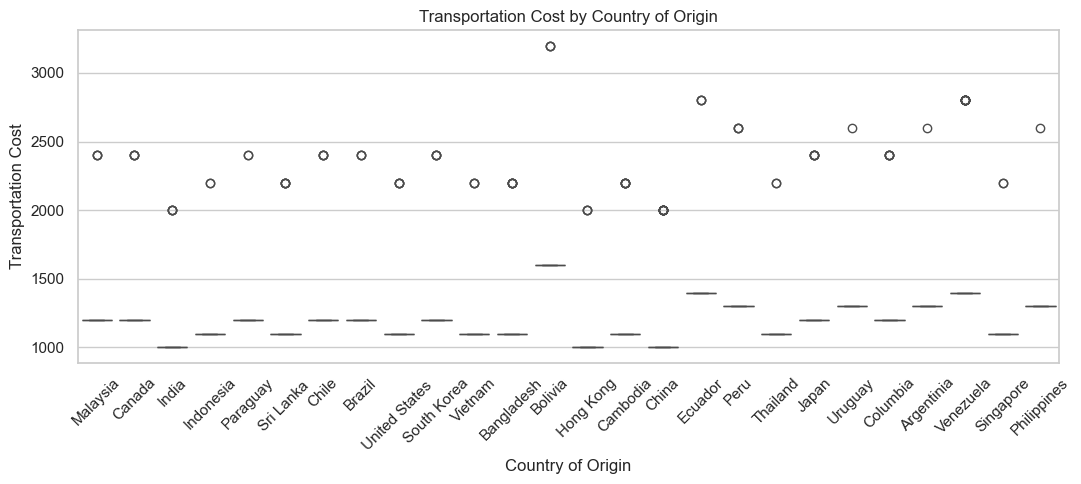

In [ ]:
plt.figure(figsize=(11, 5))
sns.boxplot(
    data=imputed_data,
    x='country',
    y='transport_cost'
)

plt.title('Transportation Cost by Country of Origin')
plt.xlabel('Country of Origin')
plt.ylabel('Transportation Cost')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


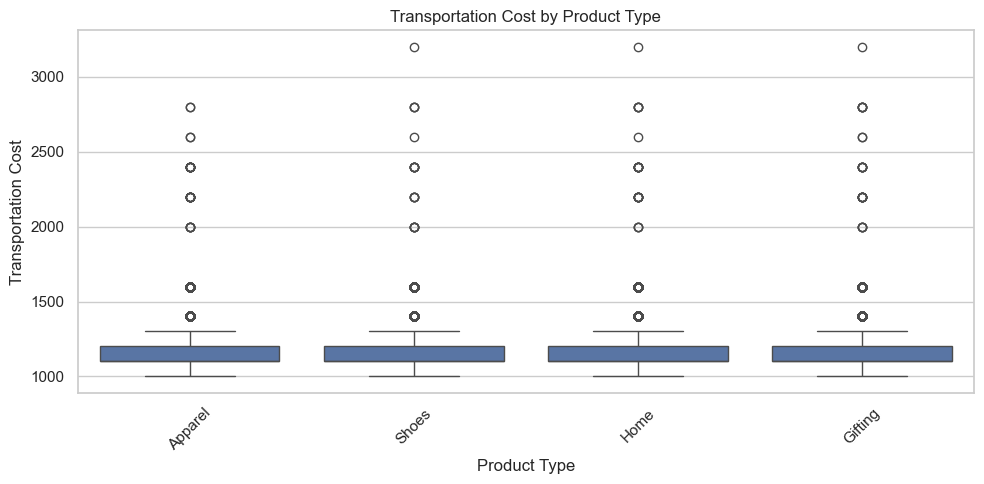

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=imputed_data,
    x='product_type',
    y='transport_cost'
)
plt.title('Transportation Cost by Product Type')
plt.xlabel('Product Type')
plt.ylabel('Transportation Cost')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
print("Highest lane rate = ", imputed_data.lane_rate.max())
print("Lowest lane rate = ", imputed_data.lane_rate.min())

Highest lane rate =  1600.0
Lowest lane rate =  1000.0


### ‼️ incorrect‼️ incorrect‼️ incorrect

Here, we have two box plots that show transportation cost by country and product type. 
* We can clearly see that the <b>highest transportation cost</b> is for an order from <b>Bangladesh</b>.

* The highest lane rate is £1600 and the lowest is £1000. The <b>lane rate of Bangladesh is £1100</b> on the lower side.


* From a previous graph, we gathered that Bangladesh is the second highest exporter of apparels but not a notable exporter of shoes, home or gifting which were pretty average compared to other countries. According to the above graph, these 3 products types cost more to transport than apparel. 

* Through the process of elimination, we can conclude that the reason the <b>transportation cost for Bangladesh is high is because of its lead time which is 77 days</b>. It is also the <b>longest lead time</b> out of all the countries.

* The <b>lowest transportation cost are from Hong Kong, China and Canada</b>. All three countries have <b>average lead time</b>. China exports the highest number of order, Canada is one of the lowest order exporters and Hong Kong falls somewhere is between based on product type. Thus, they do not share any pattern given in the datasets.

### Correction

* <b>Bolivia has the highest transportation cost which also has the highest lane rate (£1600).</b>
* It exports apparels more than other product types but there's not much of a difference. Bolivia's lead time is 60 which is average, the high transportation cost is probably because of the high lane rate.
* The <b>lowest transportation cost are from Hong Kong, China and India (not Canada)</b>. All these countries have the lowest lane rate. 

### Transportation and Storage Efficiency

We are checking the efficiency of the storage taken up by the products. We will check if the country or product type affects how efficiently the storage space is being used.

In [ ]:
imputed_data['container_efficiency'] = (imputed_data['pallets_amt'] / 54) * 100
imputed_data['container_efficiency'] = imputed_data['container_efficiency'].clip(upper=100)

imputed_data.head()

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,lane_rate,pallets_amt,storage_cost_day,containers_needed,transport_cost,container_efficiency
0,1,Apparel,2025-11-01,9839,57.6,Malaysia,2025-09-11,2025-11,2025-09,50,1200.0,53,106,1.0,1200.0,98.148148
1,2,Apparel,2026-05-01,11200,51.0,Canada,2026-02-01,2026-05,2026-02,60,1200.0,47,94,1.0,1200.0,87.037037
2,3,Apparel,2026-03-01,2353,24.0,India,2025-10-27,2026-03,2025-10,68,1000.0,22,44,1.0,1000.0,40.740741
3,4,Shoes,2025-07-01,1506,36.0,Indonesia,2025-05-05,2025-07,2025-05,65,1100.0,33,66,1.0,1100.0,61.111111
4,5,Shoes,2025-11-01,7697,25.8,Paraguay,2025-07-24,2025-11,2025-07,59,1200.0,24,48,1.0,1200.0,44.444444


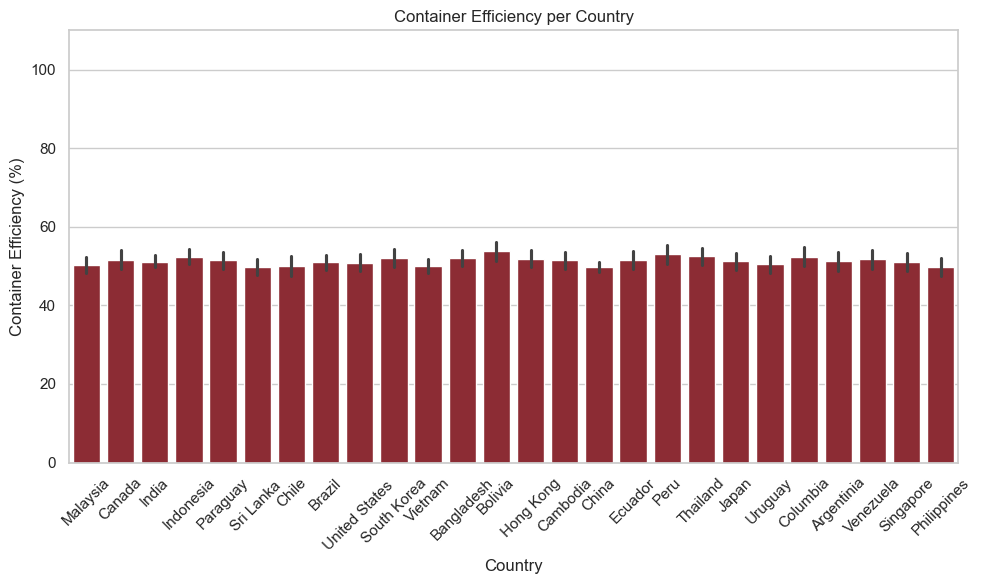

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=imputed_data,
    x='country',
    y='container_efficiency',
    color='#9c1c26'  # red for container
)

plt.ylabel("Container Efficiency (%)")
plt.xlabel("Country")
plt.title("Container Efficiency per Country")
plt.ylim(0, 110)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


* The average <b>storage efficiency</b> of each country is pretty similar at around <b>50%</b>. That is how full the containers are when they are ready for collection.

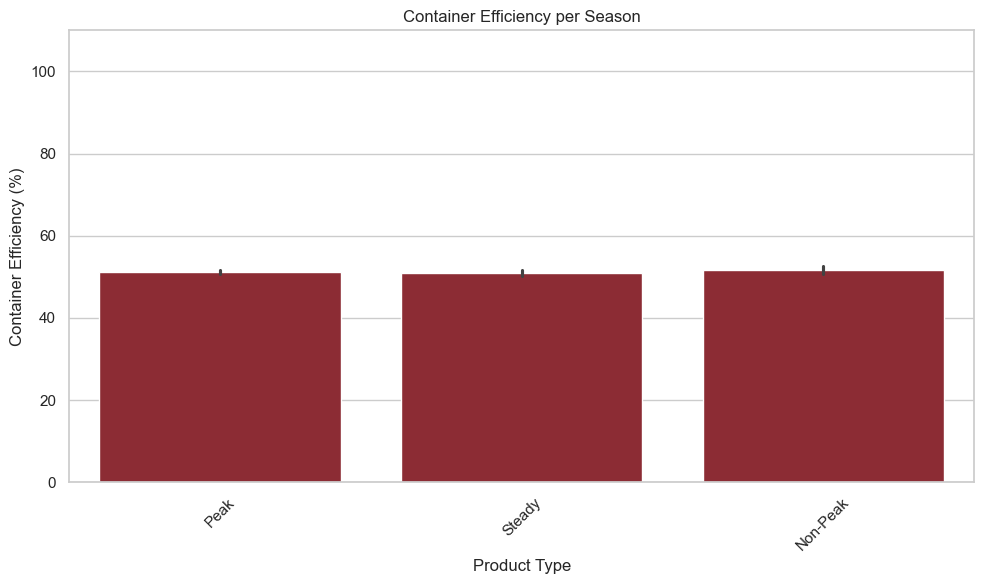

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=imputed_data,
    x='season_group',
    y='container_efficiency',
    color='#9c1c26'  # red
)

plt.ylabel("Container Efficiency (%)")
plt.xlabel("Product Type")
plt.title("Container Efficiency per Season")
plt.ylim(0, 110)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


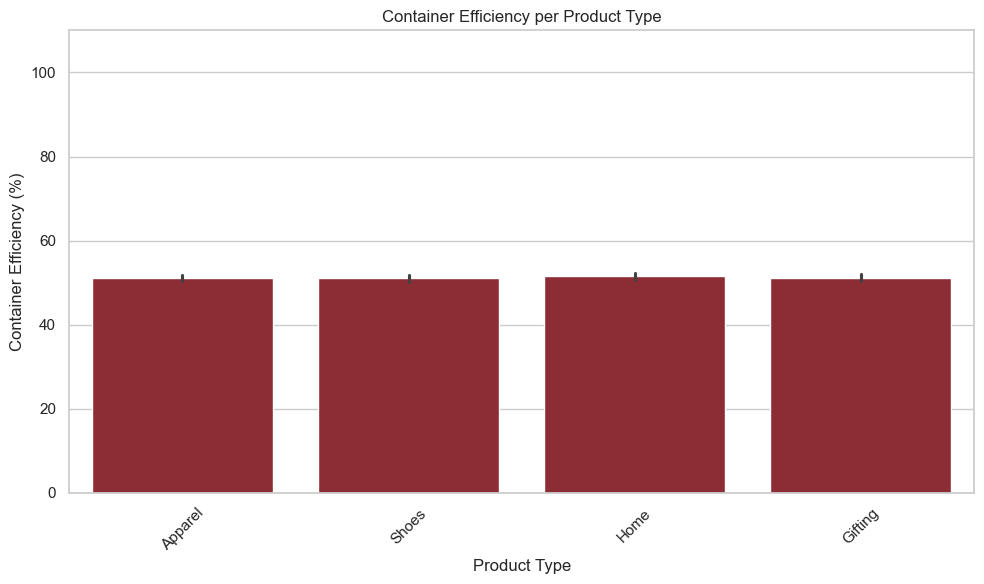

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=imputed_data,
    x='product_type',
    y='container_efficiency',
    color='#9c1c26'  # red
)

plt.ylabel("Container Efficiency (%)")
plt.xlabel("Product Type")
plt.title("Container Efficiency per Product Type")
plt.ylim(0, 110)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


* The average storage efficiency of every product type and the storage efficiency during all the seasons are similar. Thus we can tell that country, product type or season group does not affect the efficiency of how a container is used.

# Seasional Analysis

According to the graph previously made by calculating the orders per month with the help of the column month to sell, we know when the peak seasons for sales are. For some of the next analysis we are dividing the months into three groups: 
1. <b>Peak season</b> - October, September, November and December
2. <b>Non-Peak Season </b>- January, February, March and April 
3. <b>Steady Season</b> - May, June, July and August

We then calculate the volume of order per season. We can clearly see the volume of orders are higher during the peak season proving bigger orders coincide with peak season.

In [ ]:
imputed_data['sell_month'] = imputed_data['month_to_sell'].dt.month

def map_season(month):
    if month in [9, 10, 11, 12]:
        return 'Peak'
    elif month in [1, 2, 3, 4]:
        return 'Non-Peak'
    else:
        return 'Steady'

imputed_data['season_group'] = imputed_data['sell_month'].apply(map_season)

In [ ]:
season_summary = imputed_data.groupby('season_group').agg({
    'units': 'sum',
    'order_size': 'sum',
    'pallets_amt': 'sum',
    'storage_cost_day': 'sum'
}).reset_index()

print(season_summary)


  season_group     units     order_size  pallets_amt  storage_cost_day
0     Non-Peak  24450817   97686.976621        90284            180568
1         Peak  73435450  291365.075529       269265            538530
2       Steady  52671915  209385.918316       193546            387092


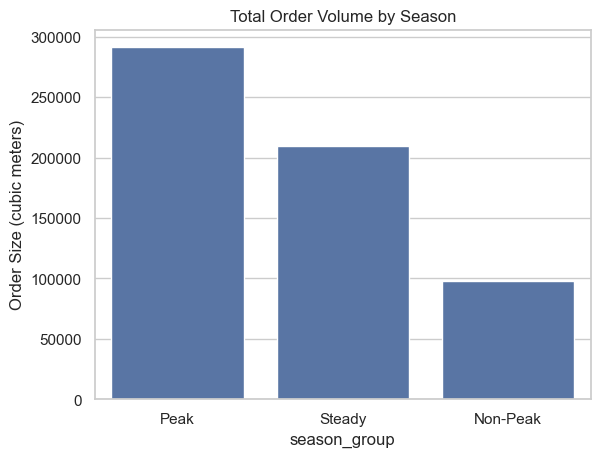

In [ ]:
sns.barplot(x='season_group', y='order_size', data=season_summary, order=['Peak','Steady','Non-Peak'])
plt.title("Total Order Volume by Season")
plt.ylabel("Order Size (cubic meters)")
plt.show()

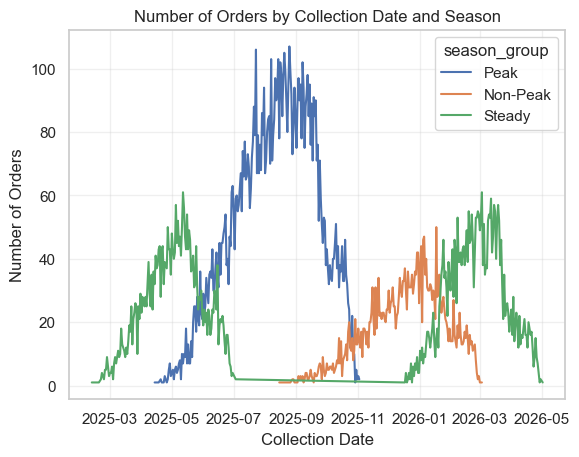

In [ ]:
orders_count = (
    imputed_data
    .groupby(['collection_date', 'season_group'])
    .size()
    .reset_index(name='num_orders')
)

sns.lineplot(
    data=orders_count,
    x='collection_date',
    y='num_orders',
    hue='season_group',
    hue_order=['Peak', 'Non-Peak', 'Steady']
)

plt.title("Number of Orders by Collection Date and Season")
plt.xlabel("Collection Date")
plt.ylabel("Number of Orders")
plt.grid(True, alpha=0.3)
plt.show()

- There graph peaks a <b>few months before the peak season/ during early peak season</b>. That is the earliest collection date after which the orders should arrive at the destination on time for month to sell.

## Product Type Each Season

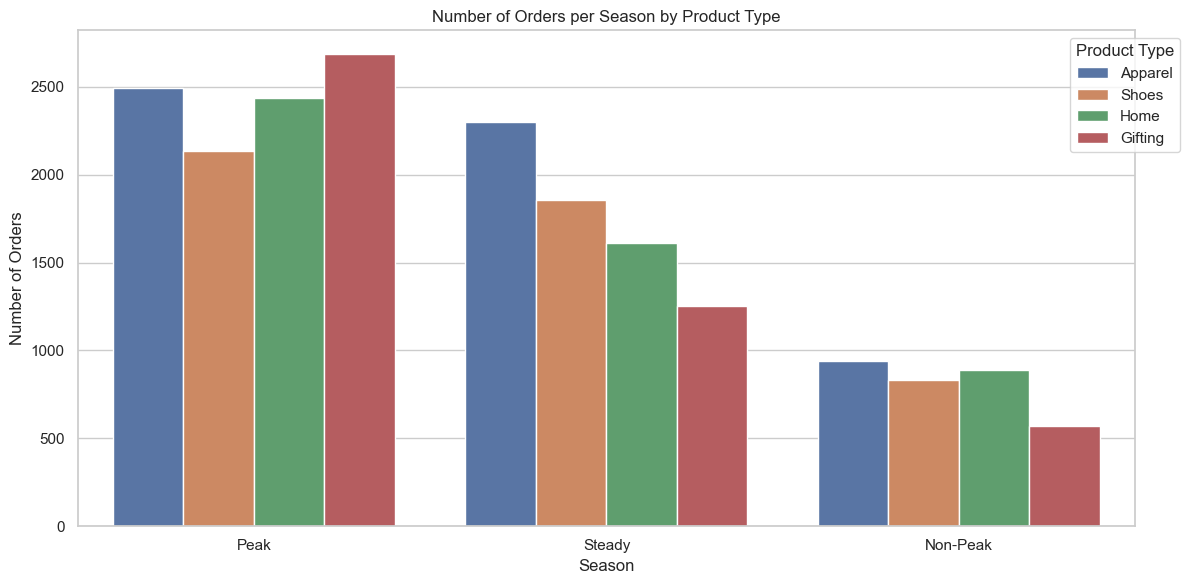

In [ ]:
plt.figure(figsize=(12,6))
sns.countplot(data=imputed_data, x='season_group', hue='product_type')
plt.title("Number of Orders per Season by Product Type")
plt.xlabel("Season")
plt.ylabel("Number of Orders")
plt.legend(title='Product Type', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

<b>Observation on peak months</b>
* During the peak months, gifting products make up the highest number of orders.
* It is follwed by apparels, then home and shoes make up the lowest number of orders.
* Gifting orders during peak season is the highest number of order for any product type during any season.


<b>Observation on steady months</b>
* During the steady season, the highest number of orders are made up of apparels which is followed by shoes, home and gifting in that order.
* The apparels and shoes order does not drop by a lot compared to during the peak months.


<b>Observation on non-peak months</b>
* During the non-peak season, all the orders are low, the lowest being gifting.
* We can see how the gifting orders go down drastically due to the end of the festive period during the peak months.
* The apparels, shoes and home don't have a significantly large difference in the number of order.
* The gifting orders during non-peak months is the lowest number of order for any product type during any season.


## Countries vs Seasons

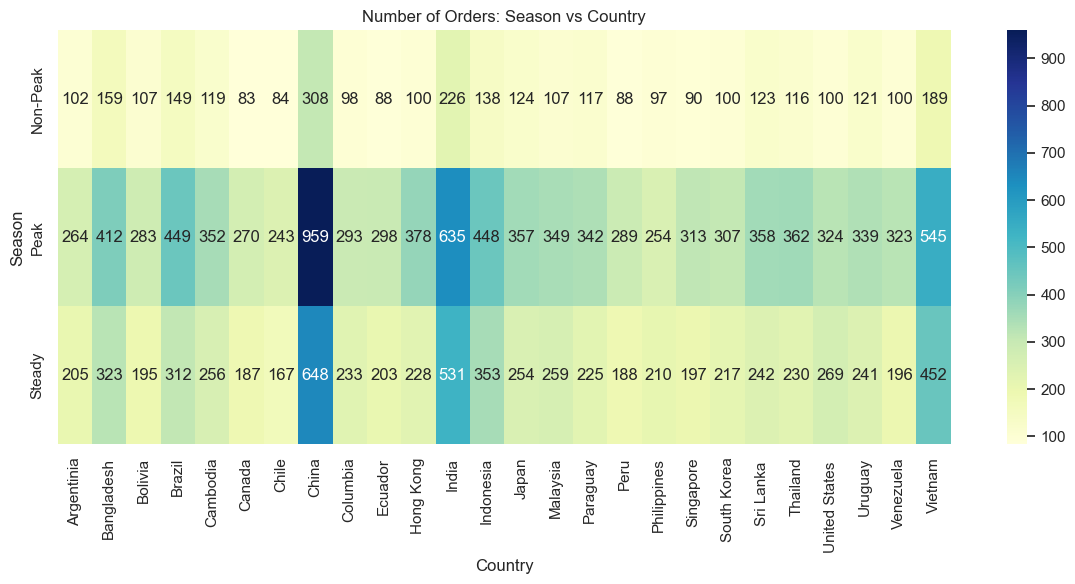

In [ ]:
season_country = imputed_data.groupby(['season_group','country']).size().unstack()
plt.figure(figsize=(12,6))
sns.heatmap(season_country, annot=True, fmt='d', cmap='YlGnBu')
plt.title("Number of Orders: Season vs Country")
plt.xlabel("Country")
plt.ylabel("Season")
plt.tight_layout()
plt.show()


<b>Observation on peak months</b>
* During the peak months, the highest number of order is from China which is also the country with the highest number of order overall. 
* It is follwed by India and then Vietnam where the second and third highest number of orders are from overall respectively.
* They are followed by Brazil, Indonesia and Bangladesh.
* Chile has the least number of order, it also has the lowest number of orders overall.
* The difference between the number of highest order and lowest order in this season is 716.

<b>Observation on non-peak months</b>
* The first, second and third highest order numbers are from China, India and Vietnam respectively.
* It is then followed by Bangladesh, Brazil and Indonesia.
* The lowest number of order during this season is from Canada who comes second to last in overall number of orders.
* The difference between the number of highest order and lowest order in this season is 225.

<b>Observation on steady months</b>
* The top 3 countries again are China, India and Vietnam in that order.
* It is follwed by Indonesia, Bangladesh and Brazil.
* The lowest number of orders is from Chile.
* The difference between the number of highest order and lowest order in this season is 481.

## Products Arrival Time

We have the <b>earliest collection date</b> and <b>lead time</b> from the datasets provided. Using those information, we can calculate when the orders arrive at the selling location <b>(arrival_date)</b>. Assuming the orders leave their country of origin at the earliest collection date, we can figure out if the orders reach their destination before or after their intended selling date. If they arrive before the <b>month to sell</b>, we categorise them as being <b>on time</b> otherwise we categorise them as being <b>delayed</b>. 

In [ ]:
imputed_data['arrival_date'] = (
    imputed_data['collection_date']
    + pd.to_timedelta(imputed_data['lead_time_days'], unit='D')
)
#imputed_data

### Delays

If the product arrives at the destination after the end of the month it was intended to be sold in, it is considered to be delayed.

In [ ]:
delays = imputed_data[imputed_data['arrival_date'] > (imputed_data['month_to_sell']+ pd.offsets.MonthEnd(0))]
delays['sell_month_end'] = delays['month_to_sell'] + pd.offsets.MonthEnd(0)
delays['delay_days'] = (delays['arrival_date'] - delays['sell_month_end']).dt.days

delay_amt = delays['order_no'].count()
delay_perc = (delay_amt/(imputed_data['order_no'].count()))*100
print("Number of delayed orders = ", delay_amt)
print("Percentage of delayed orders = ", delay_perc)
print(100-delay_perc)
delays


Number of delayed orders =  95
Percentage of delayed orders =  0.475
99.525


/var/folders/9s/5_09fzls0qzgnq0j2d4zv13w0000gn/T/ipykernel_28847/84678001.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delays['sell_month_end'] = delays['month_to_sell'] + pd.offsets.MonthEnd(0)
/var/folders/9s/5_09fzls0qzgnq0j2d4zv13w0000gn/T/ipykernel_28847/84678001.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delays['delay_days'] = (delays['arrival_date'] - delays['sell_month_end']).dt.days


,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,...,sell_month,season_group,arrival_date,delivery_status,delay_days,holding_days,arrival_month,arrival_season,storage_duration,sell_month_end
189,190,Apparel,2026-03-01,6993,28.2,Bangladesh,2026-01-20,2026-03,2026-01,77,...,3,Non-Peak,2026-04-07,Delayed,7,-7,4,Non-Peak,-96,2026-03-31
435,436,Apparel,2026-06-01,13857,17.4,Bangladesh,2026-04-18,2026-06,2026-04,77,...,6,Steady,2026-07-04,Delayed,4,-4,7,Steady,-64,2026-06-30
455,456,Home,2025-07-01,5271,54.6,China,2025-05-27,2025-07,2025-05,67,...,7,Steady,2025-08-02,Delayed,2,-2,8,Steady,-93,2025-07-31
537,538,Apparel,2025-10-01,6729,4.8,Bangladesh,2025-08-23,2025-10,2025-08,77,...,10,Peak,2025-11-08,Delayed,8,-8,11,Peak,297,2025-10-31
600,601,Apparel,2026-05-01,6952,57.6,Bangladesh,2026-03-22,2026-05,2026-03,77,...,5,Steady,2026-06-07,Delayed,7,-7,6,Steady,-37,2026-05-31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18746,18747,Apparel,2026-03-01,10115,34.2,India,2026-01-24,2026-03,2026-01,68,...,3,Non-Peak,2026-04-02,Delayed,2,-2,4,Non-Peak,-91,2026-03-31
18778,18779,Apparel,2026-05-01,8335,15.0,Bangladesh,2026-03-17,2026-05,2026-03,77,...,5,Steady,2026-06-02,Delayed,2,-2,6,Steady,-32,2026-05-31
18801,18802,Gifting,2025-09-01,7964,10.8,China,2025-07-27,2025-09,2025-07,67,...,9,Peak,2025-10-02,Delayed,2,-2,10,Peak,334,2025-09-30
19622,19623,Apparel,2026-06-01,6903,4.8,Bangladesh,2026-04-25,2026-06,2026-04,77,...,6,Steady,2026-07-11,Delayed,11,-11,7,Steady,-71,2026-06-30


According to my calculation there are <b>95 orders</b> that are <b>delayed</b>. That is <b>0.475%</b> of the 20,000 orders. The rest <b>(99.525%)</b> of the order are early or <b>on time</b>.


In [ ]:
imputed_data['delivery_status'] = np.where(imputed_data['arrival_date']> (imputed_data['month_to_sell'] + pd.offsets.MonthEnd(0)),'Delayed','On Time')
imputed_data['delay_days']  = delays['delay_days']
#imputed_data[(imputed_data['country'] == 'Bangladesh')].head(20)

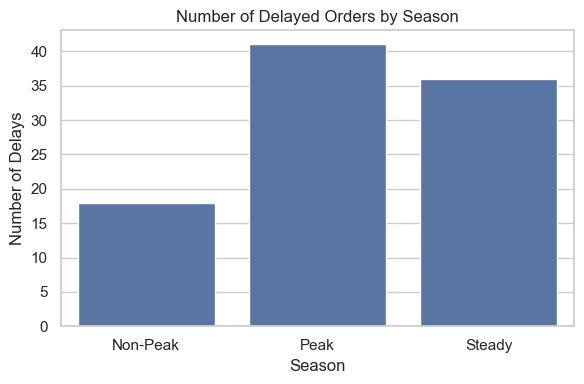

In [ ]:
delay_counts = (
    delays
    .groupby('season_group')
    .size()
    .reset_index(name='num_delays')
)

plt.figure(figsize=(6, 4))
sns.barplot(
    data=delay_counts,
    x='season_group',
    y='num_delays'
)

plt.title('Number of Delayed Orders by Season')
plt.xlabel('Season')
plt.ylabel('Number of Delays')
plt.tight_layout()
plt.show()

In [ ]:
steady = len(imputed_data[imputed_data['season_group'] == 'Steady'])
steady_delayed = len(imputed_data[imputed_data['delivery_status'] == 'Delayed'])
steady_delay_perc = (steady_delayed/steady)*100
steady_delay_perc 

1.3530836063238854

In [ ]:
peak = len(imputed_data[imputed_data['season_group'] == 'Peak'])
peak_delayed = len(imputed_data[imputed_data['delivery_status'] == 'Delayed'])
peak_delay_perc = (peak_delayed/peak)*100
peak_delay_perc 

0.9747588754360763

In [ ]:
non_peak = len(imputed_data[imputed_data['season_group'] == 'Non-Peak'])
nonpeak_delayed = len(imputed_data[imputed_data['delivery_status'] == 'Delayed'])
nonpeak_delay_perc = (nonpeak_delayed/non_peak)*100
nonpeak_delay_perc 

2.9384472626043925

In [ ]:
(steady_delayed+peak_delayed+nonpeak_delayed)/20000 * 100

1.425

* Most delays happen during the peak season but that is only because the volume of orders during peak months is more than other seasons.
* We can see that the percentage of delayed order per season is the greatest for <b>non-peak season with 2.93%</b>
* <b>1.35% of orders in steady season is delayed</b>.
* Although delayed orders in <b>peak season</b> look more than other season, the percentage of delayed order is the lowest at <b>0.97%</b>

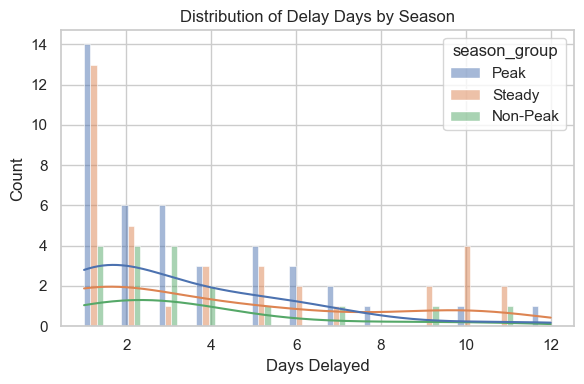

In [ ]:
plt.figure(figsize=(6, 4))
sns.histplot(
    data=imputed_data,
    x='delay_days',
    hue='season_group',
    bins=25,
    kde=True,
    multiple="dodge"
)

plt.title('Distribution of Delay Days by Season')
plt.xlabel('Days Delayed')
plt.tight_layout()
plt.show()

In [ ]:
delay_counts = delays['delay_days'].value_counts().sort_index()
print(delay_counts)


delay_days
1     31
2     15
3     11
4      8
5      8
6      5
7      4
8      1
9      3
10     5
11     3
12     1
Name: count, dtype: int64


- Most products are <b>delayed by less than 4 days</b>. The latest delay is by 12 days.
- Most orders that are delayed during <b>peak season</b> seem to be delayed by a <b>smaller duration</b>
- Delayed orders during <b>steady season</b> are delayed by <b>longer duration</b>.

### Early Orders

I calculated how early the orders arrive if they are not delayed. The average difference between the arrival date and the month to sell is about 42 days. That is then used as a threshold to categorise if the orders has arrived on time or is early. If a product arrives 42 days before its month to sell, it will be considered early.

In [ ]:
imputed_data['holding_days'] = (imputed_data['month_to_sell']  + pd.offsets.MonthEnd(0) - imputed_data['arrival_date']).dt.days
average_diff = imputed_data['holding_days'].mean()
print(f"Average difference between arrival date and month_to_sell = {average_diff:.2f} days")
print("Max difference between arrival date and month_to_sell = ", imputed_data['holding_days'].max())
print("Min difference between arrival date and month_to_sell = ", imputed_data['holding_days'].min())

Average difference between arrival date and month_to_sell = 41.43 days
Max difference between arrival date and month_to_sell =  94
Min difference between arrival date and month_to_sell =  -12


In [ ]:
imputed_data.head(10)

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,...,container_efficiency,sell_month,season_group,arrival_date,delivery_status,delay_days,holding_days,arrival_month,arrival_season,storage_duration
0,1,Apparel,2025-11-01,9839,57.6,Malaysia,2025-09-11,2025-11,2025-09,50,...,98.148148,11,Peak,2025-10-31,On Time,NaN,30,10,Peak,305
1,2,Apparel,2026-05-01,11200,51.0,Canada,2026-02-01,2026-05,2026-02,60,...,87.037037,5,Steady,2026-04-02,On Time,NaN,59,4,Non-Peak,29
2,3,Apparel,2026-03-01,2353,24.0,India,2025-10-27,2026-03,2025-10,68,...,40.740741,3,Non-Peak,2026-01-03,On Time,NaN,87,1,Non-Peak,-2
3,4,Shoes,2025-07-01,1506,36.0,Indonesia,2025-05-05,2025-07,2025-05,65,...,61.111111,7,Steady,2025-07-09,On Time,NaN,22,7,Steady,0
4,5,Shoes,2025-11-01,7697,25.8,Paraguay,2025-07-24,2025-11,2025-07,59,...,44.444444,11,Peak,2025-09-21,On Time,NaN,70,9,Peak,345
5,6,Shoes,2026-03-01,1317,28.8,Sri Lanka,2026-01-04,2026-03,2026-01,60,...,50.000000,3,Non-Peak,2026-03-05,On Time,NaN,26,3,Non-Peak,0
6,7,Apparel,2026-06-01,8733,43.8,Chile,2026-02-26,2026-06,2026-02,55,...,74.074074,6,Steady,2026-04-22,On Time,NaN,69,4,Non-Peak,9
7,8,Shoes,2026-05-01,5229,46.2,Brazil,2026-03-04,2026-05,2026-03,55,...,77.777778,5,Steady,2026-04-28,On Time,NaN,33,4,Non-Peak,3
8,9,Shoes,2025-11-01,12098,22.8,United States,2025-07-23,2025-11,2025-07,70,...,38.888889,11,Peak,2025-10-01,On Time,NaN,60,10,Peak,335
9,10,Shoes,2026-05-01,1785,30.6,Malaysia,2026-03-26,2026-05,2026-03,50,...,51.851852,5,Steady,2026-05-15,On Time,NaN,16,5,Steady,0


In [ ]:
imputed_data['arrival_month'] = imputed_data['arrival_date'].dt.month
imputed_data['arrival_season'] = imputed_data['arrival_month'].apply(map_season)

imputed_data['delivery_status'] = 'On Time'

# Delayed
imputed_data.loc[
    imputed_data['delay_days'].notna(),
    'delivery_status'
] = 'Delayed'

# Early
imputed_data.loc[
    (imputed_data['delay_days'].isna()) &
    (imputed_data['arrival_season'] != imputed_data['season_group']) &
    (imputed_data['holding_days'] >= 42),
    'delivery_status'
] = 'Early'

In [ ]:
imputed_data[imputed_data['delivery_status'] == 'Early']


,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,...,container_efficiency,sell_month,season_group,arrival_date,delivery_status,delay_days,holding_days,arrival_month,arrival_season,storage_duration
1,2,Apparel,2026-05-01,11200,51.000000,Canada,2026-02-01,2026-05,2026-02,60,...,87.037037,5,Steady,2026-04-02,Early,NaN,59,4,Non-Peak,29
6,7,Apparel,2026-06-01,8733,43.800000,Chile,2026-02-26,2026-06,2026-02,55,...,74.074074,6,Steady,2026-04-22,Early,NaN,69,4,Non-Peak,9
12,13,Apparel,2026-05-01,3223,10.800000,Vietnam,2026-02-11,2026-05,2026-02,67,...,18.518519,5,Steady,2026-04-19,Early,NaN,42,4,Non-Peak,12
14,15,Apparel,2026-06-01,14566,49.800000,South Korea,2026-02-10,2026-06,2026-02,65,...,85.185185,6,Steady,2026-04-16,Early,NaN,75,4,Non-Peak,15
20,21,Apparel,2026-05-01,7729,3.000000,Malaysia,2026-02-10,2026-05,2026-02,50,...,5.555556,5,Steady,2026-04-01,Early,NaN,60,4,Non-Peak,30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19958,19959,Home,2026-05-01,10740,31.200000,Columbia,2026-01-31,2026-05,2026-01,55,...,53.703704,5,Steady,2026-03-27,Early,NaN,65,3,Non-Peak,35
19973,19974,Apparel,2026-05-01,2939,45.000000,Vietnam,2026-01-31,2026-05,2026-01,67,...,75.925926,5,Steady,2026-04-08,Early,NaN,53,4,Non-Peak,23
19978,19979,Gifting,2026-01-01,7269,33.000000,China,2025-09-25,2026-01,2025-09,67,...,55.555556,1,Non-Peak,2025-12-01,Early,NaN,61,12,Peak,31
19991,19992,Gifting,2026-05-01,11329,44.284165,Columbia,2026-01-31,2026-05,2026-01,55,...,75.925926,5,Steady,2026-03-27,Early,NaN,65,3,Non-Peak,35


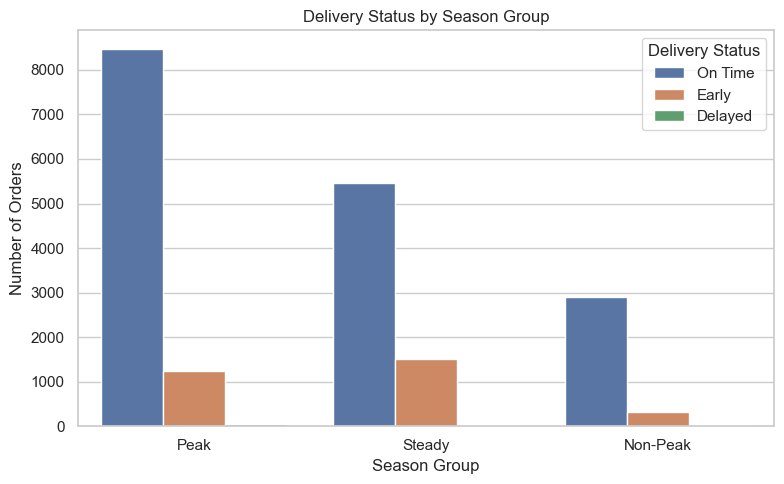

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=imputed_data,
    x='season_group',
    hue='delivery_status'
)

plt.title('Delivery Status by Season Group')
plt.xlabel('Season Group')
plt.ylabel('Number of Orders')
plt.legend(title='Delivery Status')
plt.tight_layout()
plt.show()

* There is very little number of delayed orders and most orders are on time
* Orders are more likely to arrive early during the steady season rather than peak or non-peak season. They are less likely to arrive early during the non-peak season especially.

## Early vs Delayed Storage Price

In [ ]:
# total_storage_cost = delays['pallets_amt'].sum() * 2 * 9 * 30
# int(total_storage_cost)

1457460

<b>Conditions:</b>
- If the peak seasons orders arrive before september, stock will be put out the same year otherwise it will be put out in the peak season of next year. (September to December)</p>

- If the non-peak seasons orders arrive before april, stock will be put out the same year otherwise it will be put out in the non-peak season of next year. (January to April)

- If the steady seasons orders arrive before april, stock will be put out the same year otherwise it will be put out in the steady season of next year. (May to August)

In [ ]:
def next_season_start(month_to_sell,delivery_status, arrival_date, arrival_month, sell_month, season):

    year = arrival_date.year
    if arrival_month == sell_month:
        return 0

    if delivery_status != 'Delayed':
        put_out_date = month_to_sell

    elif season == 'Peak' and delivery_status == 'Delayed' :
            put_out_date = pd.Timestamp(year=year+1, month=9, day=1)

    elif season == 'Non-Peak' and delivery_status == 'Delayed' :
            put_out_date = pd.Timestamp(year=year+1, month=1, day=1)

    elif season == 'Steady' and delivery_status == 'Delayed' :
            put_out_date = pd.Timestamp(year=year+1, month=5, day=1)

    return (put_out_date - arrival_date).days

In [ ]:
imputed_data['storage_duration'] = imputed_data.apply(
    lambda row: next_season_start(
        row['month_to_sell'],
        row['delivery_status'],
        row['arrival_date'],
        row['arrival_month'],
        row['sell_month'],
        row['season_group']
    ),
    axis=1
)



In [ ]:
imputed_data.tail(5)

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,...,container_efficiency,sell_month,season_group,arrival_date,delivery_status,delay_days,holding_days,arrival_month,arrival_season,storage_duration
19995,19996,Apparel,2025-10-01,13680,27.0,Bolivia,2025-07-01,2025-10,2025-07,60,...,46.296296,10,Peak,2025-08-30,Early,NaN,62,8,Steady,32
19996,19997,Shoes,2025-07-01,6492,17.4,Venezuela,2025-03-29,2025-07,2025-03,56,...,29.629630,7,Steady,2025-05-24,On Time,NaN,68,5,Steady,38
19997,19998,Gifting,2025-12-01,2088,25.8,China,2025-09-30,2025-12,2025-09,67,...,44.444444,12,Peak,2025-12-06,On Time,NaN,25,12,Peak,0
19998,19999,Apparel,2025-09-01,9207,30.0,Brazil,2025-07-28,2025-09,2025-07,55,...,51.851852,9,Peak,2025-09-21,On Time,NaN,9,9,Peak,0
19999,20000,Gifting,2025-12-01,9508,2.4,Argentinia,2025-09-20,2025-12,2025-09,50,...,5.555556,12,Peak,2025-11-09,On Time,NaN,52,11,Peak,22


In [ ]:
imputed_data[imputed_data['delivery_status'] == 'Delayed']

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,...,container_efficiency,sell_month,season_group,arrival_date,delivery_status,delay_days,holding_days,arrival_month,arrival_season,storage_duration
189,190,Apparel,2026-03-01,6993,28.2,Bangladesh,2026-01-20,2026-03,2026-01,77,...,48.148148,3,Non-Peak,2026-04-07,Delayed,7.0,-7,4,Non-Peak,269
435,436,Apparel,2026-06-01,13857,17.4,Bangladesh,2026-04-18,2026-06,2026-04,77,...,29.629630,6,Steady,2026-07-04,Delayed,4.0,-4,7,Steady,301
455,456,Home,2025-07-01,5271,54.6,China,2025-05-27,2025-07,2025-05,67,...,92.592593,7,Steady,2025-08-02,Delayed,2.0,-2,8,Steady,272
537,538,Apparel,2025-10-01,6729,4.8,Bangladesh,2025-08-23,2025-10,2025-08,77,...,9.259259,10,Peak,2025-11-08,Delayed,8.0,-8,11,Peak,297
600,601,Apparel,2026-05-01,6952,57.6,Bangladesh,2026-03-22,2026-05,2026-03,77,...,98.148148,5,Steady,2026-06-07,Delayed,7.0,-7,6,Steady,328
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18746,18747,Apparel,2026-03-01,10115,34.2,India,2026-01-24,2026-03,2026-01,68,...,59.259259,3,Non-Peak,2026-04-02,Delayed,2.0,-2,4,Non-Peak,274
18778,18779,Apparel,2026-05-01,8335,15.0,Bangladesh,2026-03-17,2026-05,2026-03,77,...,25.925926,5,Steady,2026-06-02,Delayed,2.0,-2,6,Steady,333
18801,18802,Gifting,2025-09-01,7964,10.8,China,2025-07-27,2025-09,2025-07,67,...,18.518519,9,Peak,2025-10-02,Delayed,2.0,-2,10,Peak,334
19622,19623,Apparel,2026-06-01,6903,4.8,Bangladesh,2026-04-25,2026-06,2026-04,77,...,9.259259,6,Steady,2026-07-11,Delayed,11.0,-11,7,Steady,294


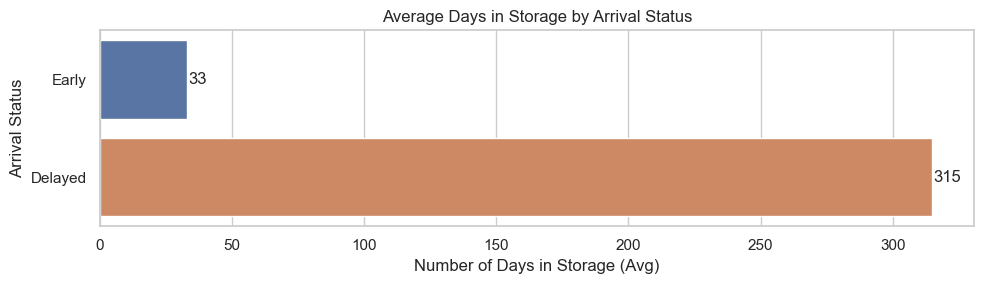

In [ ]:
early_storage_avg = round(
    imputed_data[imputed_data['delivery_status'] == 'Early']['storage_duration'].mean(), 0
)

delayed_storage_avg = round(
    imputed_data[imputed_data['delivery_status'] == 'Delayed']['storage_duration'].mean(), 0
)



storage_duration_avg = pd.DataFrame({
    'Arrival Status': ['Early', 'Delayed'],
    'Number of Days in Storage (Avg)': [early_storage_avg, delayed_storage_avg]
})


plt.figure(figsize=(10, 3))
sns.barplot(
    x='Number of Days in Storage (Avg)',
    y='Arrival Status',
    hue ='Arrival Status',
    legend=False,
    data=storage_duration_avg,
)


for index, value in enumerate(storage_duration_avg['Number of Days in Storage (Avg)']):
    if pd.notna(value):
        plt.text(value + 0.5, index, f"{int(value)}", va='center')


plt.title('Average Days in Storage by Arrival Status')
plt.xlabel('Number of Days in Storage (Avg)')
plt.ylabel('Arrival Status')

plt.tight_layout()
plt.show()

This is a comparison of average storage duration of <b>early stock vs delayed stock</b>. If we choose to store the products until it is time for them to be put out, delayed products would need to be stored for another year. On average, that is 285 days. On the other hand, average storage days for early stock is only 33 days. 

In [ ]:
imputed_data[imputed_data['delivery_status'] == 'Delayed']['storage_duration'].max(), 0

(np.int64(608), 0)

In [ ]:
imputed_data.head()

,order_no,product_type,month_to_sell,units,order_size,country,collection_date,SellingDate,ColDate,lead_time_days,...,container_efficiency,sell_month,season_group,arrival_date,delivery_status,delay_days,holding_days,arrival_month,arrival_season,storage_duration
0,1,Apparel,2025-11-01,9839,57.6,Malaysia,2025-09-11,2025-11,2025-09,50,...,98.148148,11,Peak,2025-10-31,On Time,NaN,30,10,Peak,1
1,2,Apparel,2026-05-01,11200,51.0,Canada,2026-02-01,2026-05,2026-02,60,...,87.037037,5,Steady,2026-04-02,Early,NaN,59,4,Non-Peak,29
2,3,Apparel,2026-03-01,2353,24.0,India,2025-10-27,2026-03,2025-10,68,...,40.740741,3,Non-Peak,2026-01-03,On Time,NaN,87,1,Non-Peak,57
3,4,Shoes,2025-07-01,1506,36.0,Indonesia,2025-05-05,2025-07,2025-05,65,...,61.111111,7,Steady,2025-07-09,On Time,NaN,22,7,Steady,0
4,5,Shoes,2025-11-01,7697,25.8,Paraguay,2025-07-24,2025-11,2025-07,59,...,44.444444,11,Peak,2025-09-21,On Time,NaN,70,9,Peak,41


In [ ]:
imputed_data['storage_cost'] = (imputed_data['pallets_amt'] *2 *imputed_data['storage_duration'])

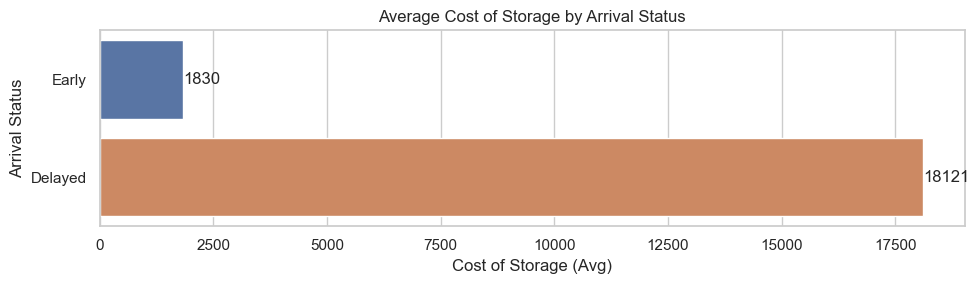

In [ ]:
early_storage_cost_avg = round(
    imputed_data[imputed_data['delivery_status'] == 'Early']['storage_cost'].mean(), 0
)

delayed_storage_cost_avg = round(
    imputed_data[imputed_data['delivery_status'] == 'Delayed']['storage_cost'].mean(), 0
)

storage_cost_avg = pd.DataFrame({
    'Arrival Status': ['Early', 'Delayed'],
    'Cost of Storage (Avg)': [early_storage_cost_avg, delayed_storage_cost_avg]
})


plt.figure(figsize=(10, 3))
sns.barplot(
    x='Cost of Storage (Avg)',
    y='Arrival Status',
    hue ='Arrival Status',
    legend=False,
    data=storage_cost_avg
)


for index, value in enumerate(storage_cost_avg['Cost of Storage (Avg)']):
    if pd.notna(value):
        plt.text(value + 0.5, index, f"{int(value)}", va='center')


plt.title('Average Cost of Storage by Arrival Status')
plt.xlabel('Cost of Storage (Avg)')
plt.ylabel('Arrival Status')

plt.tight_layout()
plt.show()

In [ ]:
delayed = imputed_data[imputed_data['delivery_status'] == 'Delayed']
delayed.loc[delayed['storage_cost'].idxmax()]

order_no                               8140
product_type                          Shoes
month_to_sell           2025-12-01 00:00:00
units                                  8104
order_size                             57.6
country                             Vietnam
collection_date         2025-10-26 00:00:00
SellingDate                         2025-12
ColDate                             2025-10
lead_time_days                           67
lane_rate                            1100.0
pallets_amt                              53
storage_cost_day                        106
containers_needed                       1.0
transport_cost                       1100.0
container_efficiency              98.148148
sell_month                               12
season_group                           Peak
arrival_date            2026-01-01 00:00:00
delivery_status                     Delayed
delay_days                              1.0
holding_days                             -1
arrival_month                   

On average, the cost of storage of early orders are significantly lower that of the delayed orders. We can see the <b>average cost of storage for a delayed order</b> if it is stored until it's season next year, is about <b>£18,000</b> (‼️CORRECTION). On the other hand, the <b>orders that are early</b> can be put out in the next few months of it's arrival which means it costs less to store it for a shorter time. According to the graph, the average cost of storage for early orders is about <b>£1,800</b>.

In [ ]:
early_avg = imputed_data[imputed_data['delivery_status'] == 'Early']['storage_cost'].mean()
delayed_avg = imputed_data[imputed_data['delivery_status'] == 'Delayed']['storage_cost'].mean()
print("Average storage cost of early orders = £", early_avg)
print("Average storage cost of delayed orders = £", delayed_avg)

difference = delayed_avg - early_avg
percent_diff = (difference / early_avg) * 100
print(f"Delayed orders are {percent_diff:.1f}% more expensive than early orders on average")

ratio = delayed_avg / early_avg
print(f"Delayed orders cost {ratio:.2f} times as much as early orders on average")


Average storage cost of early orders = £ 1830.0573103223705
Average storage cost of delayed orders = £ 18121.284210526315
Delayed orders are 890.2% more expensive than early orders on average
Delayed orders cost 9.90 times as much as early orders on average


According to my calculations, the delayed orders will cost about 8.77 times more than orders that are early that is if they are stored to put out next time its season rolls around. Let's see what happens if the products are flowed out regardless if it is in season or not.

## Selling Delayed Orders as Off-season Stocks 

### Markdown

To examine what happens if instead of storing the orders that are delayed, we push them to stores, we will make some assumptions for the test. 
* An average price of £30 for all units
* Ideally, the products are meant to be marked down in 6 weeks duration by an average of 33% so we will assume that percentage for initial markdown
* The units have not sold due to it being off-season
  
We will then calculate the amount of money lost in markdowns vs if they were sold in season. 

In [ ]:
avg_delayed_units = imputed_data.loc[imputed_data['delivery_status'] == 'Delayed']['units'].mean()
product_price = 30
initial_markdown = 33
delayed_orders_cost = avg_delayed_units * product_price * (initial_markdown/100)

print(delayed_orders_cost)
print("Intended cost of the delayed orders = ", avg_delayed_units * product_price)

76967.39368421053
Intended cost of the delayed orders =  233234.5263157895


* While the profit made from selling the products should have been more than £233,000, we lose almost £77k in the initial markdowns and will keep losing a certain percent of the remaining amount in subsequential weeks.
* The cost of putting out the stock during off-season is greater than the cost of storage.
* Even if we assume the product price to be £20 or £10, we lose £51k and £25k respectively which is still greater than the cost of storage.


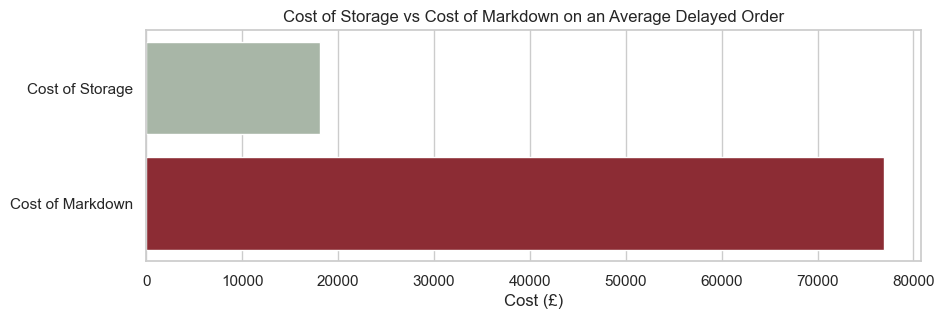

In [ ]:
storage_vs_md = {
    'Cost of Storage': delayed_storage_cost_avg,
    'Cost of Markdown': delayed_orders_cost
}

# Convert to DataFrame for Seaborn
df = pd.DataFrame(list(storage_vs_md.items()), columns=['Metric', 'Cost'])

# Plot
plt.figure(figsize=(10, 3))
sns.barplot(data=df, x='Cost', y='Metric', hue= 'Metric', palette=['#A6B8A5', '#9c1c26'])

plt.xlabel("Cost (£)")
plt.ylabel("")
plt.title("Cost of Storage vs Cost of Markdown on an Average Delayed Order")
plt.show()


<b>The cost of selling the delayed products off season is 4.8 times more than the cost of storage. </b>

## Correlation

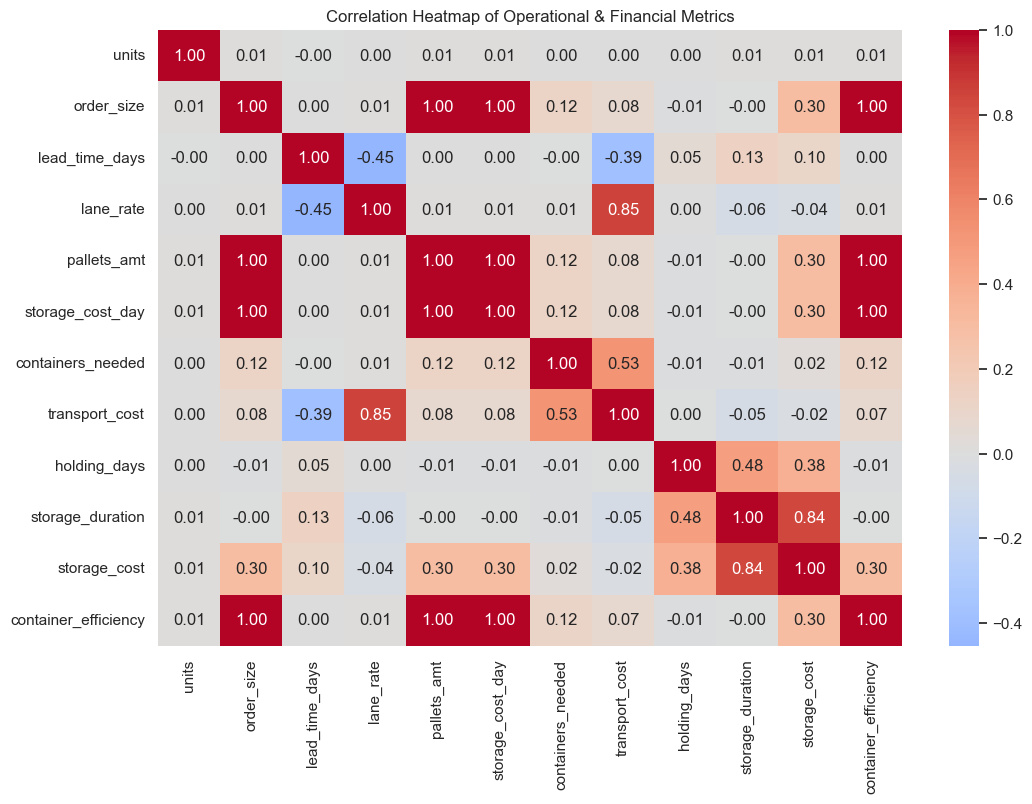

In [ ]:
cols_to_corr = [
    'units', 'order_size', 'lead_time_days', 'lane_rate', 'pallets_amt',
    'storage_cost_day', 'containers_needed', 'transport_cost', 
    'holding_days', 'storage_duration', 'storage_cost', 'container_efficiency'
]

corr_matrix = imputed_data[cols_to_corr].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Operational & Financial Metrics")
plt.show()

Some notable correlation between the columns as between:
- storage cost and storage duration -> high positive correlation
- transportation cost and lead time -> moderate negative correlation 
- transport cost and lane rate -> moderate positive correlation
- lane rate and lead time -> high negative correlation (the more the lead time, the less the lane rate) 
- container efficiency and pallet amount -> high positive correlation
- container efficiency and order size -> high positive correlation 
- container efficiency and storage cost per day -> high positive correlation (due to high number of pallets)

Now let's check the correlation between the these columns and country.

In [ ]:

numeric_cols = [
    'units', 'order_size', 'lead_time_days', 'lane_rate', 'pallets_amt',
    'storage_cost_day', 'containers_needed', 'transport_cost', 
    'holding_days', 'storage_duration', 'storage_cost', 'container_efficiency'
]

corr_df = imputed_data[numeric_cols].copy()
country_dummies = pd.get_dummies(imputed_data['country'], prefix='country')
corr_df = pd.concat([corr_df, country_dummies], axis=1)
print(corr_df.head())


   units  order_size  lead_time_days  lane_rate  pallets_amt  \
0   9839        57.6              50     1200.0           53   
1  11200        51.0              60     1200.0           47   
2   2353        24.0              68     1000.0           22   
3   1506        36.0              65     1100.0           33   
4   7697        25.8              59     1200.0           24   

   storage_cost_day  containers_needed  transport_cost  holding_days  \
0               106                1.0          1200.0            30   
1                94                1.0          1200.0            59   
2                44                1.0          1000.0            87   
3                66                1.0          1100.0            22   
4                48                1.0          1200.0            70   

   storage_duration  ...  country_Peru  country_Philippines  \
0                 1  ...         False                False   
1                29  ...         False                Fa

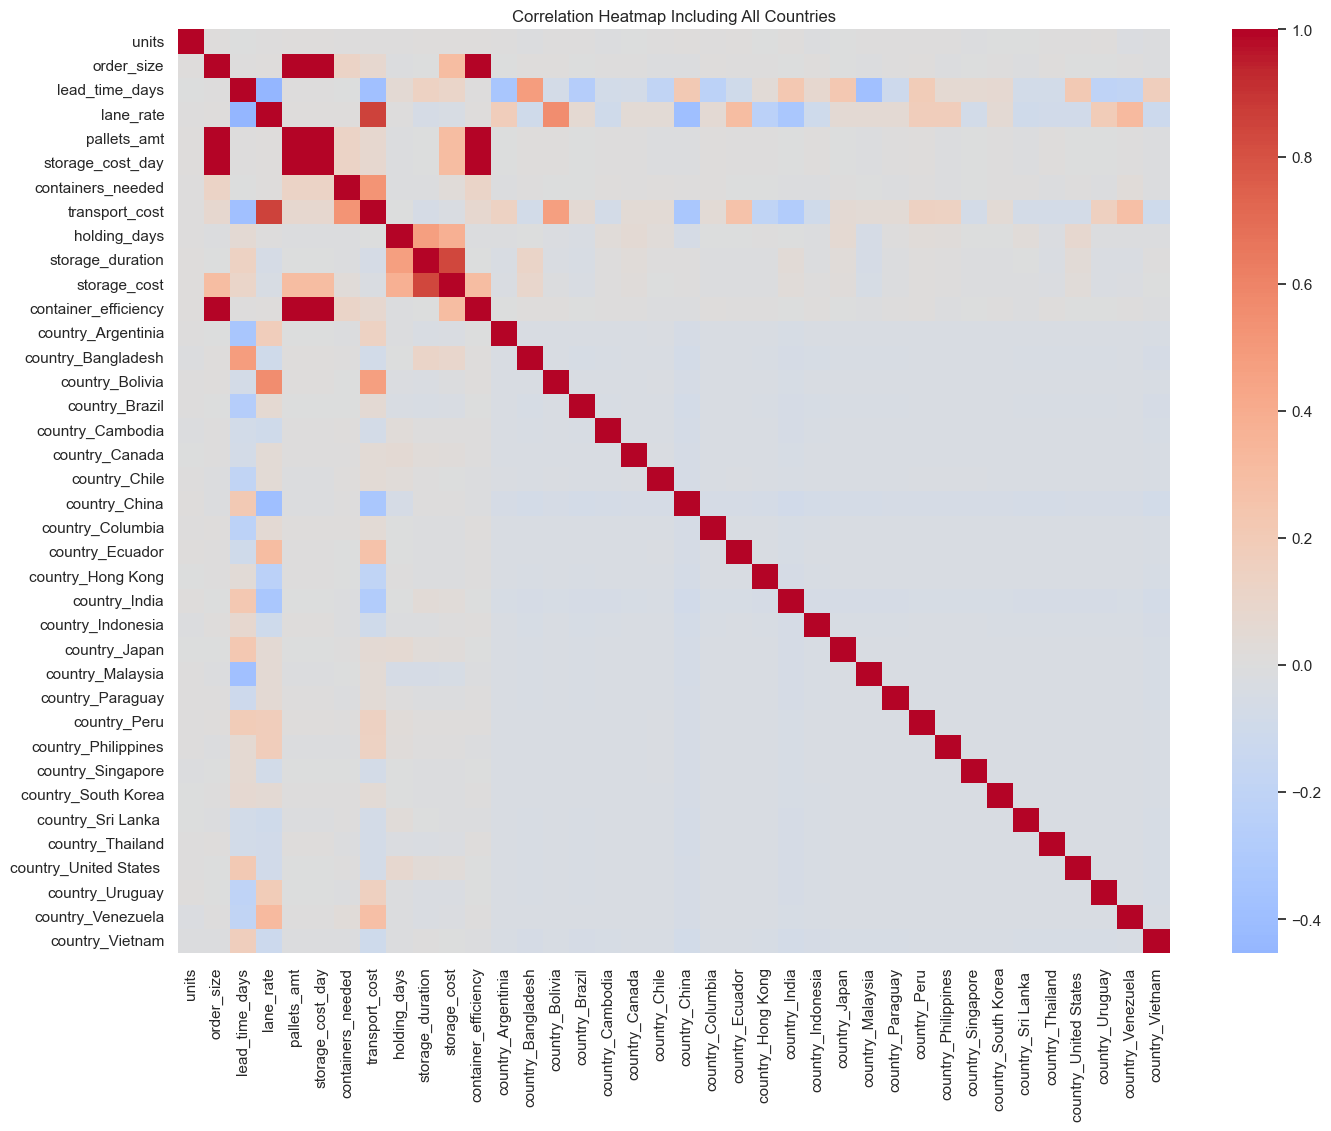

In [ ]:
corr_matrix = corr_df.corr()

plt.figure(figsize=(16, 12))  # larger figure because many countries
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap Including All Countries")
plt.show()


Each country is independent of other countries. 

### Further Insights and Suggestions


- The average container efficiency is around 50% which is not ideal. We need to prioritize capacity planning.
- Lane rates need to be negotiated with countries that export a large amount of order as well as some countries with a low lead time as we saw in the correlation chart, lead time and lane rate have a moderate negative correlation
- Since gifting products have the highest peak and the lowest dip, planning should be prioritised on that front. As we saw, being early is better than orders being delayed. Gifting is the most profitable product type during the most profitable month. If it is delayed, the store will suffer the worse due to extra charges (storage or markdown).
- If necessary, utilise non-peak season to optimise storage efficiency by delaying some orders